# MIB sketching baseline: a controlled GPT-2 Small experiment

Can inexpensive approximations predict the causal effects of intervening on model components?
This notebook studies **eight attention heads, one prompt, and one scalar score** before attempting
the MIB benchmark. It measures exact singleton/pair effects, fits first- and second-order
surrogates, and explores random directional measurements. All reported results are computed here.

**Run:** use the project's Python 3.11 `.venv` kernel with the dependencies in section 2 installed,
then **Restart Kernel and Run All**. The first model load may download GPT-2 weights/tokenizer.
Run from the project directory; section 22 creates a unique subdirectory under `results/`.
No installation commands execute automatically. If section 1 cannot import a dependency,
follow section 2's setup instructions before rerunning.

**Memory:** batch size one, a short prompt, FP32, inference without autograd, and selective
activation caching. FP32 is intentional for finite differences. A CUDA-enabled PyTorch build
uses the GPU; CPU execution also works. After changing the prompt, model, score, or components,
restart and run all cells to invalidate every cached measurement.

## 1. Environment and GPU check

Record the environment and seed every random-number generator. Fixed seeds make mask sampling
reproducible; exact numerical reproducibility across GPU hardware/library versions is not promised.
CUDA memory readings describe PyTorch's allocator, not all memory used by other processes.

In [1]:
import sys
import random
import time
import torch
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available(), "| selected device:", device)
if device == "cuda":
    gpu = torch.cuda.get_device_properties(torch.cuda.current_device())
    print("GPU:", gpu.name)
    print(f"Total VRAM: {gpu.total_memory / 2**30:.2f} GiB")
    print(f"Allocated: {torch.cuda.memory_allocated() / 2**20:.1f} MiB")
    print(f"Reserved:  {torch.cuda.memory_reserved() / 2**20:.1f} MiB")
else:
    print("CPU fallback. A CUDA-enabled PyTorch kernel is needed to use the RTX 3060.")

Python: 3.11.5 (tags/v3.11.5:cce6ba9, Aug 24 2023, 14:38:34) [MSC v.1936 64 bit (AMD64)]
PyTorch: 2.14.1+cu126
CUDA available: True | selected device: cuda
GPU: NVIDIA GeForce RTX 3060
Total VRAM: 12.00 GiB
Allocated: 0.0 MiB
Reserved:  0.0 MiB


## 2. Install/import dependencies

Run these commands manually in the environment used by your notebook kernel, if needed:

```bash
# From this project directory (the existing .venv uses Python 3.11):
# ./.venv/Scripts/python.exe -m pip install -r requirements.txt
# ./.venv/Scripts/python.exe -m ipykernel install --sys-prefix --name mib-sketching --display-name "Python (mib-sketching CUDA)"
# ./.venv/Scripts/python.exe -m jupyterlab
# Select the "Python (mib-sketching CUDA)" notebook kernel.
# Headless execution: ./.venv/Scripts/python.exe run_notebook.py
```

`requirements.txt` pins the CUDA 12.6 PyTorch build and the notebook dependencies.
TransformerLens 2.16.1 requires NumPy below 2 on Python 3.11; the requirements retain this
constraint. The plain `python` command on this machine points to a different environment,
so use the explicit project interpreter above. The headless runner saves real cell outputs
to `mib_sketching_baseline.executed.ipynb` and keeps this source notebook clear for reruns.

The requested `HookedTransformer.from_pretrained` API is retained by the pinned
[TransformerLens 2.16.1 release](https://pypi.org/project/transformer-lens/2.16.1/).
TransformerLens 4 removed that class; see its
[release notes](https://transformerlensorg.github.io/TransformerLens/content/news/release-4.0.html).
This notebook deliberately uses the requested API, with runtime hook discovery and shape checks.
The Transformers pin keeps the legacy loading path consistent. Restart the kernel after installing.

In [2]:
import itertools
import json
import re
import warnings
from contextlib import contextmanager
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from uuid import uuid4

import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from tqdm.auto import tqdm
from IPython.display import display

try:
    from transformer_lens import HookedTransformer, utils as tl_utils
except (ImportError, AttributeError) as exc:
    raise ImportError(
        "This notebook requires the legacy HookedTransformer API. Use the pinned "
        "TransformerLens/Transformers environment in section 2 and restart the kernel."
    ) from exc

PACKAGES = ["torch", "transformer-lens", "transformers", "datasets", "pyarrow", "numpy", "pandas",
            "matplotlib", "scipy", "scikit-learn", "tqdm"]
package_versions = {name: version(name) for name in PACKAGES}
display(pd.DataFrame(package_versions.items(), columns=["package", "version"]))

PROMPT = "The capital of France is"
CORRECT_TOKEN = " Paris"
INCORRECT_TOKEN = " London"
N_TRAIN, N_TEST = 64, 32
ABLATION_PROBABILITY = 0.3
EPSILON = 0.05
SKETCH_BUDGETS = [4, 8, 16, 32, 64]
RUN_LOCAL_GRADIENT_CHECK = True  # Extra 2*n diagnostic forwards; not sketch acquisition.
RUN_CURVATURE = True            # Reuses sketch endpoints; no extra forward passes.
RESULTS_ROOT = Path("results")
figures = {}


def synchronize_cuda():
    if device == "cuda":
        torch.cuda.synchronize()


def release_cuda_cache():
    # Call after deleting large temporary tensors, not after every short forward pass.
    if device == "cuda":
        torch.cuda.empty_cache()


class CostTracker:
    """Count actual notebook forwards; cache hits never increment model_evaluations."""
    def __init__(self):
        synchronize_cuda()
        self.started = time.perf_counter()
        self.model_evaluations = 0
        self.mask_requests = 0
        self.mask_cache_hits = 0
        self.forward_seconds = 0.0
        self.peak_allocated_mib = 0.0 if device == "cuda" else np.nan
        self.peak_reserved_mib = 0.0 if device == "cuda" else np.nan
        self.stage_name = "unscoped"
        self.stages = []
        self.forward_log = []

    def capture_peak(self):
        if device == "cuda":
            self.peak_allocated_mib = max(self.peak_allocated_mib,
                                         torch.cuda.max_memory_allocated() / 2**20)
            self.peak_reserved_mib = max(self.peak_reserved_mib,
                                        torch.cuda.max_memory_reserved() / 2**20)

    @contextmanager
    def stage(self, name):
        if self.stage_name != "unscoped":
            raise RuntimeError("CostTracker stages must not be nested.")
        synchronize_cuda()
        if device == "cuda":
            self.capture_peak()
            torch.cuda.reset_peak_memory_stats()
        started = time.perf_counter()
        before = (self.model_evaluations, self.mask_requests, self.mask_cache_hits)
        self.stage_name = name
        try:
            yield
        finally:
            synchronize_cuda()
            self.capture_peak()
            self.stages.append({
                "stage": name,
                "model_evaluations": self.model_evaluations - before[0],
                "mask_requests": self.mask_requests - before[1],
                "mask_cache_hits": self.mask_cache_hits - before[2],
                "wall_seconds": time.perf_counter() - started,
                "peak_allocated_mib": (torch.cuda.max_memory_allocated() / 2**20
                                       if device == "cuda" else np.nan),
                "peak_reserved_mib": (torch.cuda.max_memory_reserved() / 2**20
                                      if device == "cuda" else np.nan),
            })
            self.stage_name = "unscoped"

    def forward(self, operation):
        synchronize_cuda()
        started = time.perf_counter()
        self.model_evaluations += 1
        success = False
        try:
            with torch.no_grad():
                result = operation()
            success = True
            return result
        finally:
            synchronize_cuda()
            elapsed = time.perf_counter() - started
            self.forward_seconds += elapsed
            self.capture_peak()
            self.forward_log.append({"stage": self.stage_name,
                                     "wall_seconds": elapsed, "success": success})

    def summary(self):
        synchronize_cuda()
        self.capture_peak()
        return {"model_evaluations": self.model_evaluations,
                "mask_requests": self.mask_requests,
                "mask_cache_hits": self.mask_cache_hits,
                "forward_seconds": self.forward_seconds,
                "elapsed_wall_seconds": time.perf_counter() - self.started,
                "peak_allocated_mib": self.peak_allocated_mib,
                "peak_reserved_mib": self.peak_reserved_mib}


costs = CostTracker()


def run_model(model, tokens, mode="plain", **kwargs):
    """The only entry point for all notebook-initiated model forward passes."""
    if mode == "plain":
        return costs.forward(lambda: model(tokens, **kwargs))
    if mode == "cache":
        return costs.forward(lambda: model.run_with_cache(tokens, **kwargs))
    if mode == "hooks":
        return costs.forward(lambda: model.run_with_hooks(tokens, **kwargs))
    raise ValueError(f"Unknown forward mode: {mode}")

,package,version
0,torch,2.14.1+cu126
1,transformer-lens,2.16.1
2,transformers,4.51.3
3,datasets,3.6.0
4,pyarrow,20.0.0
5,numpy,1.26.4
6,pandas,2.3.3
7,matplotlib,3.11.2
8,scipy,1.17.1
9,scikit-learn,1.9.1


## 3. Load GPT-2 Small with TransformerLens

Load the requested model in FP32 and evaluation mode. No optimizer or parameter gradients
are needed. Configuration values, rather than hardcoded architecture sizes, drive later checks.
The accounting starts before model loading; loading time/memory are recorded separately from forwards.

In [3]:
with costs.stage("model loading"):
    model = HookedTransformer.from_pretrained("gpt2-small", device=device, dtype=torch.float32)
    model = model.to(device)
    model.eval()
    model.requires_grad_(False)

print("Layers:", model.cfg.n_layers)
print("Attention heads per layer:", model.cfg.n_heads)
print("d_model:", model.cfg.d_model)
print("Parameter dtype:", next(model.parameters()).dtype)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Loaded pretrained model gpt2-small into HookedTransformer
Moving model to device:  cuda
Layers: 12
Attention heads per layer: 12
d_model: 768
Parameter dtype: torch.float32


## 4. Basic model sanity check

Tokenize the factual prompt and inspect the five most likely next tokens. Probabilities come
from the softmax over the entire vocabulary, not just these five candidates. The logit vector
is discarded after inspection.

In [4]:
tokens = model.to_tokens(PROMPT, prepend_bos=True).to(device)
print("Prompt:", repr(PROMPT), "| token shape:", tuple(tokens.shape))
with costs.stage("sanity check"):
    logits = run_model(model, tokens)
    last_logits = logits[0, -1].float()
    top_logits, top_ids = torch.topk(last_logits, 5)
    all_probabilities = last_logits.softmax(dim=-1)
    top_predictions = pd.DataFrame({
        "token_id": top_ids.cpu().tolist(),
        "token": [repr(model.tokenizer.decode([i])) for i in top_ids.cpu().tolist()],
        "logit": top_logits.cpu().tolist(),
        "probability": all_probabilities[top_ids].cpu().tolist(),
    })
display(top_predictions)
del logits, last_logits, top_logits, top_ids, all_probabilities
release_cuda_cache()

Prompt: 'The capital of France is' | token shape: (1, 6)


,token_id,token,logit,probability
0,783,' now',14.389958,0.047506
1,262,' the',14.152020,0.037447
2,257,' a',14.097540,0.035461
3,1363,' home',13.960544,0.030921
4,287,' in',13.824113,0.026978


## 5. Cache internal activations

Circuit discovery examines internal components such as attention heads and directed edges.
Here we intervene on each head's attention-weighted value output `z`, before its output projection,
at **all token positions**. Zeroing `z` removes that head's projected contribution while keeping
the shared attention output bias intact. This is a head-level experiment, not edge discovery.

Inspect `model.hook_dict` before registering hooks. Prefer available `hook_z` names; an enabled
`hook_result` (per-head projected output) is a supported fallback. The layouts are
`hook_z: [batch, position, n_heads, d_head]` and
`hook_result: [batch, position, n_heads, d_model]`. Shape checks verify both the head and width
dimensions and reject a merged attention output. Cache only one residual stream and one head-output tensor
on CPU to keep memory conservative.
These layouts match the [TransformerLens 2.16.1 attention implementation](https://raw.githubusercontent.com/TransformerLensOrg/TransformerLens/v2.16.1/transformer_lens/components/abstract_attention.py).

In [5]:
def print_hook_diagnostics(model):
    print("TransformerLens version:", package_versions["transformer-lens"])
    print("Available hook names:")
    for name in sorted(model.hook_dict):
        print(" ", name)
    print("Expected head tensor: [batch, position, head, d_head or d_model].")
    print("If the API changed, update resolve_head_hook/HEAD_HOOK_OVERRIDES only after")
    print("checking the tensor semantics and shape; do not substitute merged attn_out.")


# For an explicitly inspected API variant, map layer -> its per-head hook name here.
HEAD_HOOK_OVERRIDES = {}


def hook_is_in_layer(name, layer):
    return re.search(rf"(?:^|\.)(?:blocks|layers|h)\.{layer}\.", name) is not None


def resolve_head_hook(model, layer):
    available = model.hook_dict
    if layer in HEAD_HOOK_OVERRIDES:
        name = HEAD_HOOK_OVERRIDES[layer]
        if name not in available:
            print_hook_diagnostics(model)
            raise KeyError(f"Override hook does not exist: {name}")
        if not hook_is_in_layer(name, layer) or not name.endswith(("hook_z", "hook_result")):
            raise ValueError("Override must identify a supported per-head output in the requested layer.")
        if name.endswith("hook_result"):
            if not hasattr(model, "set_use_attn_result"):
                raise RuntimeError("This API cannot enable per-head result hooks. Inspect its hook implementation.")
            model.set_use_attn_result(True)
        return name
    for kind in ("z", "result"):
        expected = tl_utils.get_act_name(kind, layer)
        matches = [name for name in available
                   if hook_is_in_layer(name, layer) and name.endswith(f"hook_{kind}")]
        name = expected if expected in available else (matches[0] if len(matches) == 1 else None)
        if name is not None:
            if kind == "result":
                if not hasattr(model, "set_use_attn_result"):
                    continue
                model.set_use_attn_result(True)
            return name
    print_hook_diagnostics(model)
    raise RuntimeError(f"No supported per-head output hook found for layer {layer}.")


def validate_head_activation(model, hook_name, activation):
    if hook_name.endswith("hook_z"):
        expected_width = model.cfg.d_head
    elif hook_name.endswith("hook_result"):
        expected_width = model.cfg.d_model
    else:
        raise ValueError(f"Unsupported per-head output semantics: {hook_name}")
    if activation.ndim != 4 or tuple(activation.shape[2:]) != (model.cfg.n_heads, expected_width):
        print_hook_diagnostics(model)
        raise RuntimeError(
            f"Unexpected layout at {hook_name}: {tuple(activation.shape)}; expected "
            f"[batch, position, {model.cfg.n_heads}, {expected_width}]."
        )


head_hook_names = {layer: resolve_head_hook(model, layer) for layer in range(model.cfg.n_layers)}
residual_names = [name for name in model.hook_dict if name.endswith("hook_resid_post")]
if not residual_names:
    print_hook_diagnostics(model)
    raise RuntimeError("No residual hook found. Inspect and update the residual-name filter.")
residual_name = residual_names[0]
head_name = head_hook_names[0]
with costs.stage("activation cache inspection"):
    cached_logits, activation_cache = run_model(
        model, tokens, mode="cache", names_filter=[residual_name, head_name], device="cpu"
    )
    print("Available hook points:", len(model.hook_dict))
    print("Cached activations (intentionally filtered):", len(activation_cache))
    print(residual_name, tuple(activation_cache[residual_name].shape))
    head_shape = tuple(activation_cache[head_name].shape)
    print(head_name, head_shape)
    validate_head_activation(model, head_name, activation_cache[head_name])
del cached_logits, activation_cache
release_cuda_cache()

Available hook points: 280
Cached activations (intentionally filtered): 2
blocks.0.hook_resid_post (1, 6, 768)
blocks.0.attn.hook_z (1, 6, 12, 64)


**API diagnostic cell.** If a hook-related experiment fails, run the cell below independently.
It prints the available names even when later experimental cells cannot execute. Correct the
resolver/override mapping based on actual tensor semantics, then restart and run all cells.

In [6]:
# Change to True to print the complete hook inventory, or call the function after an error.
SHOW_ALL_HOOKS = False
if SHOW_ALL_HOOKS:
    print_hook_diagnostics(model)
else:
    print("Resolved head-output hooks:", head_hook_names)

Resolved head-output hooks: {0: 'blocks.0.attn.hook_z', 1: 'blocks.1.attn.hook_z', 2: 'blocks.2.attn.hook_z', 3: 'blocks.3.attn.hook_z', 4: 'blocks.4.attn.hook_z', 5: 'blocks.5.attn.hook_z', 6: 'blocks.6.attn.hook_z', 7: 'blocks.7.attn.hook_z', 8: 'blocks.8.attn.hook_z', 9: 'blocks.9.attn.hook_z', 10: 'blocks.10.attn.hook_z', 11: 'blocks.11.attn.hook_z'}


## 6. Define a causal intervention

`ablate_attention_heads(model, tokens, components, metric_fn)` returns a scalar and attaches
temporary hooks for just one forward pass. Heads are grouped by layer, so multiple heads in
the same layer are scaled together. Clone only the small activation being changed; do not mutate
weights or retain activations. The generalized scaling helper will also support section 19.
At the hooked tensor, unselected head slices are copied without modification. Their values at
later layers may still change as a causal consequence of an earlier intervention.

In [7]:
def validate_components(model, components):
    normalized = []
    for component in components:
        if len(component) != 2 or not all(isinstance(x, (int, np.integer)) for x in component):
            raise ValueError(f"Expected an integer (layer, head) pair, got {component!r}.")
        layer, head = map(int, component)
        if not (0 <= layer < model.cfg.n_layers and 0 <= head < model.cfg.n_heads):
            raise ValueError(f"Component {(layer, head)} is outside the model configuration.")
        normalized.append((layer, head))
    if len(set(normalized)) != len(normalized):
        raise ValueError("Components must be distinct.")
    return normalized


def scale_selected_head_outputs(activation, head_scales):
    """Copy the activation, assigning only requested head slices on axis 2."""
    edited = activation.clone()
    for head, scale in head_scales.items():
        edited[:, :, head, :] = activation[:, :, head, :] * scale
    return edited


def scaled_head_score(model, tokens, components, scales, metric_fn):
    components = validate_components(model, components)
    scales = np.asarray(scales, dtype=np.float64)
    if scales.shape != (len(components),) or not np.isfinite(scales).all():
        raise ValueError("One finite scale is required for each component.")
    by_layer = {}
    for (layer, head), scale in zip(components, scales):
        by_layer.setdefault(layer, {})[head] = float(scale)
    hooks = []
    fired = set()

    def make_hook(layer, selected):
        def scale_hook(activation, hook):
            validate_head_activation(model, hook.name, activation)
            if tuple(activation.shape[:2]) != tuple(tokens.shape):
                raise RuntimeError(f"Unexpected batch/position dimensions at {hook.name}.")
            fired.add(layer)
            return scale_selected_head_outputs(activation, selected)
        return scale_hook

    for layer, selected in by_layer.items():
        hooks.append((resolve_head_hook(model, layer), make_hook(layer, selected)))
    logits = None
    try:
        with torch.no_grad():
            logits = run_model(model, tokens, mode="hooks", fwd_hooks=hooks, reset_hooks_end=True)
            if fired != set(by_layer):
                print_hook_diagnostics(model)
                raise RuntimeError(f"Some registered hooks did not fire: {set(by_layer) - fired}")
            score = metric_fn(logits)
            if isinstance(score, torch.Tensor):
                if score.numel() != 1:
                    raise ValueError("metric_fn must return one scalar.")
                score = score.detach().item()
            score = float(score)
        if not np.isfinite(score):
            raise ValueError("The intervention metric is not finite.")
        return score
    finally:
        del logits


def ablate_attention_heads(model, tokens, components, metric_fn):
    return scaled_head_score(model, tokens, components, np.zeros(len(components)), metric_fn)

## 7. Define a scalar model score

Use $\operatorname{logit}(\text{ Paris})-\operatorname{logit}(\text{ London})$ at the last
position. A positive value favors Paris. The leading spaces matter for GPT-2 tokenization.
Verify both candidates are single tokens; silently taking the first token of a multi-token
candidate would define a different score.
The canonical GPT-2 [vocabulary](https://huggingface.co/openai-community/gpt2/resolve/main/vocab.json)
and [BPE merges](https://huggingface.co/openai-community/gpt2/resolve/main/merges.txt) encode
`" Paris"` as `[6342]` and `" London"` as `[3576]`, so the next-token logit difference is appropriate.
The code still derives IDs from the loaded tokenizer and validates exact decoding rather than hardcoding them.

In [8]:
def single_token_id(model, text):
    ids = model.to_tokens(text, prepend_bos=False).reshape(-1)
    if ids.numel() != 1:
        raise ValueError(f"{text!r} produces {ids.numel()} tokens; select a single-token candidate.")
    token_id = int(model.to_single_token(text))
    if token_id != int(ids.item()):
        raise RuntimeError("Tokenizer helper methods disagree.")
    decoded = model.tokenizer.decode([token_id], clean_up_tokenization_spaces=False)
    if decoded != text:
        raise ValueError(f"Candidate failed exact token round-trip: {text!r} -> {decoded!r}.")
    return token_id


correct_id = single_token_id(model, CORRECT_TOKEN)
incorrect_id = single_token_id(model, INCORRECT_TOKEN)
assert correct_id != incorrect_id
print("Candidate IDs:", {CORRECT_TOKEN: correct_id, INCORRECT_TOKEN: incorrect_id})
display(pd.DataFrame([
    {"candidate": repr(text), "token_id": token_id, "n_tokens": 1,
     "decoded": repr(model.tokenizer.decode([token_id], clean_up_tokenization_spaces=False))}
    for text, token_id in [(CORRECT_TOKEN, correct_id), (INCORRECT_TOKEN, incorrect_id)]
]))


def logit_difference(logits):
    return (logits[:, -1, correct_id] - logits[:, -1, incorrect_id]).mean()


with costs.stage("baseline score"):
    baseline_score = ablate_attention_heads(model, tokens, [], logit_difference)
print(f"Baseline Paris-minus-London score: {baseline_score:.6f}")

Candidate IDs: {' Paris': 6342, ' London': 3576}


,candidate,token_id,n_tokens,decoded
0,' Paris',6342,1,' Paris'
1,' London',3576,1,' London'


Baseline Paris-minus-London score: 1.890848


## 8. Choose a small set of attention heads

Edit the list below to change the components, then restart and run all cells. This deterministic
selection is independent of observed effects and is not claimed to identify the best circuit.
A binary NumPy mask has shape `(n,)`: **1 = ablated; 0 = unchanged**.

In [9]:
COMPONENTS = [(0, 0), (1, 1), (2, 2), (3, 3), (4, 4), (5, 5), (6, 6), (7, 7)]
components = validate_components(model, COMPONENTS)
n = len(components)
if n < 2:
    raise ValueError("Use at least two components for the pairwise experiment.")
component_names = [f"L{layer}H{head}" for layer, head in components]
pair_indices = list(itertools.combinations(range(n), 2))
assert len(pair_indices) == n * (n - 1) // 2
assert len(set(pair_indices)) == len(pair_indices) and all(i < j for i, j in pair_indices)
zero_mask = np.zeros(n, dtype=np.int8)
print("n =", n, "| components:", component_names)
print("Quadratic feature count:", n + len(pair_indices))

n = 8 | components: ['L0H0', 'L1H1', 'L2H2', 'L3H3', 'L4H4', 'L5H5', 'L6H6', 'L7H7']
Quadratic feature count: 36


## 9. Implement $F(\mathrm{mask})$

Cache scalar results by immutable mask tuples. The baseline already computed in section 7 seeds
the all-zero entry. `evaluate_mask` validates binary input before converting it to component IDs.
The repeated direct baseline below bypasses the cache to verify hooks do not persist after ablation.
Every actual forward, including this check, is counted and timed with CUDA synchronization.

In [10]:
mask_cache = {tuple(zero_mask.tolist()): baseline_score}


def mask_key(mask):
    array = np.asarray(mask)
    if array.shape != (n,) or not np.isin(array, [0, 1]).all():
        raise ValueError(f"Expected a binary mask of shape {(n,)}, got {array!r}.")
    return tuple(int(value) for value in array)


def evaluate_mask(mask):
    key = mask_key(mask)
    costs.mask_requests += 1
    if key in mask_cache:
        costs.mask_cache_hits += 1
        return mask_cache[key]
    selected = [components[i] for i, bit in enumerate(key) if bit]
    score = ablate_attention_heads(model, tokens, selected, logit_difference)
    mask_cache[key] = score
    return score


with costs.stage("mask and hook sanity checks"):
    first_mask = zero_mask.copy()
    first_mask[0] = 1
    print("F(0):", evaluate_mask(zero_mask))
    print("F(e_0):", evaluate_mask(first_mask))
    restored_score = ablate_attention_heads(model, tokens, [], logit_difference)
    np.testing.assert_allclose(restored_score, baseline_score, rtol=1e-5, atol=1e-5)
    calls_before = costs.model_evaluations
    evaluate_mask(first_mask)
    assert costs.model_evaluations == calls_before, "Duplicate mask unexpectedly ran the model."
print("Baseline restored after ablation; duplicate-mask cache verified.")

F(0): 1.890848159790039
F(e_0): 1.723160743713379


Baseline restored after ablation; duplicate-mask cache verified.

## 10. Exact first-order intervention effects

Compute $\Delta_i=F(e_i)-F(0)$ for each selected head. Negative effects mean that removing
the head reduces the Paris-versus-London score. These are full finite ablations, not gradients.
Display by absolute effect, but retain a component-indexed array for later computations.

In [11]:
with costs.stage("exact single interventions"):
    single_rows = []
    for i, (layer, head) in enumerate(tqdm(components, desc="Singleton interventions")):
        mask = zero_mask.copy()
        mask[i] = 1
        score = evaluate_mask(mask)
        single_rows.append({"component_index": i, "layer": layer, "head": head,
                            "component": component_names[i], "baseline_score": baseline_score,
                            "ablated_score": score, "effect": score - baseline_score})
single_effects = pd.DataFrame(single_rows)
single_effects["absolute_effect"] = single_effects["effect"].abs()
exact_effects = single_effects.sort_values("component_index")["effect"].to_numpy()
single_effects = single_effects.sort_values("absolute_effect", ascending=False).reset_index(drop=True)
display(single_effects)

Singleton interventions:   0%|          | 0/8 [00:00<?, ?it/s]

,component_index,layer,head,component,baseline_score,ablated_score,effect,absolute_effect
0,3,3,3,L3H3,1.890848,2.133544,0.242696,0.242696
1,1,1,1,L1H1,1.890848,2.127287,0.236439,0.236439
2,4,4,4,L4H4,1.890848,1.705101,-0.185747,0.185747
3,0,0,0,L0H0,1.890848,1.723161,-0.167687,0.167687
4,2,2,2,L2H2,1.890848,1.996079,0.105231,0.105231
5,5,5,5,L5H5,1.890848,1.823886,-0.066962,0.066962
6,6,6,6,L6H6,1.890848,1.874113,-0.016735,0.016735
7,7,7,7,L7H7,1.890848,1.887799,-0.003049,0.003049


## 11. Exact pairwise interactions

For each pair, compute $\Delta_{ij}=F(e_i+e_j)-F(0)$ and compare with the additive prediction
$\Delta_i+\Delta_j$. The difference is a discrete interaction at the unablated baseline.
Nonzero interactions show where adding isolated effects misses the joint effect; they need not
equal continuous Hessian entries or coefficients fitted over the full mask distribution.

In [12]:
with costs.stage("exact pair interventions"):
    pair_rows = []
    for i, j in tqdm(pair_indices, desc="Pair interventions"):
        mask = zero_mask.copy()
        mask[[i, j]] = 1
        true_effect = evaluate_mask(mask) - baseline_score
        prediction = exact_effects[i] + exact_effects[j]
        interaction = true_effect - prediction
        pair_rows.append({"i": i, "j": j, "layer_i": components[i][0], "head_i": components[i][1],
                          "layer_j": components[j][0], "head_j": components[j][1],
                          "component_i": component_names[i], "component_j": component_names[j],
                          "true_pair_effect": true_effect, "first_order_prediction": prediction,
                          "interaction": interaction, "absolute_interaction": abs(interaction)})
pairwise_interactions = pd.DataFrame(pair_rows).sort_values(
    "absolute_interaction", ascending=False).reset_index(drop=True)
display(pairwise_interactions.head(10))

Pair interventions:   0%|          | 0/28 [00:00<?, ?it/s]

,i,j,layer_i,head_i,layer_j,head_j,component_i,component_j,true_pair_effect,first_order_prediction,interaction,absolute_interaction
0,1,5,1,1,5,5,L1H1,L5H5,0.309232,0.169477,0.139755,0.139755
1,3,5,3,3,5,5,L3H3,L5H5,0.239493,0.175734,0.063760,0.063760
2,1,2,1,1,2,2,L1H1,L2H2,0.397051,0.341670,0.055381,0.055381
3,5,6,5,5,6,6,L5H5,L6H6,-0.135029,-0.083697,-0.051332,0.051332
4,0,3,0,0,3,3,L0H0,L3H3,0.125599,0.075008,0.050591,0.050591
5,1,4,1,1,4,4,L1H1,L4H4,0.001936,0.050692,-0.048756,0.048756
6,1,3,1,1,3,3,L1H1,L3H3,0.445366,0.479135,-0.033769,0.033769
7,0,1,0,0,1,1,L0H0,L1H1,0.040741,0.068751,-0.028010,0.028010
8,2,5,2,2,5,5,L2H2,L5H5,0.012806,0.038269,-0.025463,0.025463
9,0,5,0,0,5,5,L0H0,L5H5,-0.212779,-0.234650,0.021871,0.021871


## 12. Visualize pairwise interaction matrix

The symmetric matrix displays signed interaction strengths. Its diagonal is masked because a
head paired with itself is not a distinct two-head experiment. Matplotlib's default color map
is used; a colorbar gives the numerical scale.

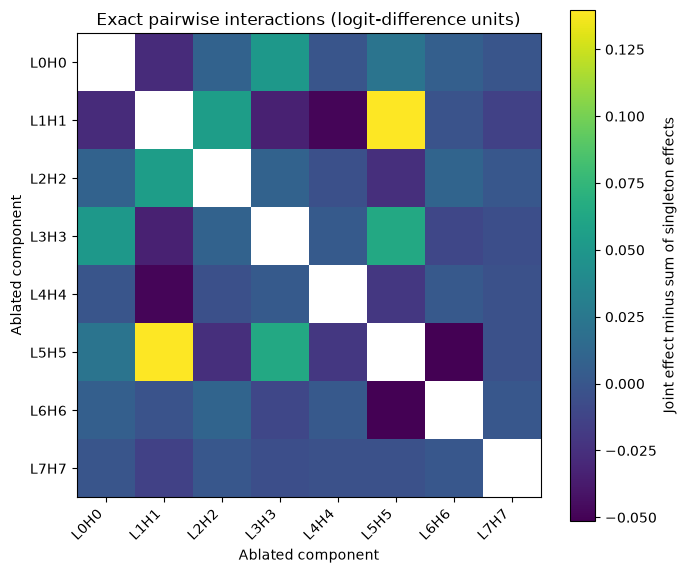

In [13]:
interaction_matrix = np.full((n, n), np.nan)
for row in pairwise_interactions.itertuples():
    interaction_matrix[row.i, row.j] = interaction_matrix[row.j, row.i] = row.interaction
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(np.ma.masked_invalid(interaction_matrix))
ax.set_xticks(range(n), component_names, rotation=45, ha="right")
ax.set_yticks(range(n), component_names)
ax.set_xlabel("Ablated component")
ax.set_ylabel("Ablated component")
ax.set_title("Exact pairwise interactions (logit-difference units)")
fig.colorbar(im, ax=ax, label="Joint effect minus sum of singleton effects")
fig.tight_layout()
figures["pairwise_interaction_matrix"] = fig
plt.show()
plt.close(fig)

## 13. Generate random intervention masks

Draw 64 **unique** masks with Bernoulli(0.3) proposals, forcing the all-zero mask into training.
Rejection of duplicates means this is sampling without replacement from the proposal distribution,
not 64 independent Bernoulli draws. Previously measured singleton/pair masks can reuse their cached
scores. Cached labels do not become training data unless their masks are in this training set.

In [14]:
def sample_unique_masks(count, n_components, probability, seed, excluded=(), include_zero=False):
    if not 0 < probability < 1:
        raise ValueError("Ablation probability must lie strictly between 0 and 1.")
    blocked = {tuple(int(v) for v in mask) for mask in excluded}
    if count < 1 or count > 2**n_components - len(blocked):
        raise ValueError("Requested split exceeds the available binary-mask space.")
    rng = np.random.default_rng(seed)
    selected, seen = [], set(blocked)
    zero = (0,) * n_components
    if include_zero:
        if zero in seen:
            raise ValueError("Cannot include an excluded zero mask.")
        selected.append(zero)
        seen.add(zero)
    attempts, max_attempts = 0, max(10000, 1000 * count)
    while len(selected) < count and attempts < max_attempts:
        key = tuple((rng.random(n_components) < probability).astype(np.int8).tolist())
        attempts += 1
        if key not in seen:
            selected.append(key)
            seen.add(key)
    if len(selected) != count:
        raise RuntimeError("Unique-mask sampling exhausted its budget. Reduce counts or adjust p.")
    return np.asarray(selected, dtype=np.int8)


def evaluate_mask_dataset(masks, description):
    rows = []
    for mask in tqdm(masks, desc=description):
        score = evaluate_mask(mask)
        rows.append({"mask": tuple(int(x) for x in mask), "score": score,
                     "score_change": score - baseline_score,
                     "n_ablated": int(mask.sum())})
    return pd.DataFrame(rows)


if N_TRAIN + N_TEST > 2**n:
    raise ValueError("Train and test counts exceed the number of unique masks.")
train_masks = sample_unique_masks(N_TRAIN, n, ABLATION_PROBABILITY, SEED, include_zero=True)
with costs.stage("random-mask training acquisition"):
    train_data = evaluate_mask_dataset(train_masks, "Training masks")
display(train_data.head())
print("Unique training masks:", len(train_data), "| mean ablated:", train_data.n_ablated.mean())

Training masks:   0%|          | 0/64 [00:00<?, ?it/s]

,mask,score,score_change,n_ablated
0,"(0, 0, 0, 0, 0, 0, 0, 0)",1.890848,0.000000,0
1,"(0, 0, 0, 0, 1, 0, 0, 0)",1.705101,-0.185747,1
2,"(1, 0, 0, 0, 0, 0, 0, 1)",1.719482,-0.171366,2
3,"(0, 1, 0, 0, 0, 0, 0, 0)",2.127287,0.236439,1
4,"(0, 1, 0, 1, 1, 0, 0, 0)",2.115657,0.224809,3


Unique training masks: 64 | mean ablated: 2.8125


## 14. Create train/test split

Use a different deterministic seed for 32 held-out masks and exclude every training mask.
Do not tune components, epsilon, or measurement budgets using these test labels. Some test labels
may already be in the exact-intervention cache; their values are still never used for fitting.
The split tests unseen interventions on this one prompt, not generalization across prompts.
Excluding the training set changes the test proposal distribution and can increase its mean
ablation count; inspect the displayed densities rather than assuming identical split distributions.

In [15]:
test_masks = sample_unique_masks(N_TEST, n, ABLATION_PROBABILITY, SEED + 1, excluded=train_masks)
train_keys = {tuple(mask) for mask in train_masks}
test_keys = {tuple(mask) for mask in test_masks}
assert len(train_keys) == N_TRAIN and len(test_keys) == N_TEST
assert train_keys.isdisjoint(test_keys)
assert tuple(zero_mask) in train_keys and tuple(zero_mask) not in test_keys
with costs.stage("held-out test acquisition"):
    test_data = evaluate_mask_dataset(test_masks, "Held-out masks")
X_train, X_test = train_masks.astype(float), test_masks.astype(float)
y_train = train_data["score_change"].to_numpy()
y_test = test_data["score_change"].to_numpy()
display(pd.DataFrame({"split": ["train", "test"], "unique_masks": [len(train_keys), len(test_keys)],
                      "mean_n_ablated": [train_data.n_ablated.mean(), test_data.n_ablated.mean()]}))

Held-out masks:   0%|          | 0/32 [00:00<?, ?it/s]

,split,unique_masks,mean_n_ablated
0,train,64,2.81250
1,test,32,3.28125


## 15. First-order approximation model

Fit $F(z)-F(0)\approx\sum_i\beta_i z_i$ without an intercept so the zero mask predicts zero
change. Fitted coefficients summarize this training distribution; they need not equal exact
singleton effects. Report MAE, Pearson correlation, Spearman correlation, and coefficient of
determination $R^2$ on the held-out masks. Constant-vector correlations are undefined (`NaN`).

First-order training design: shape=(64, 8), rank=8/8, condition=2.93


,method,MAE,Pearson,Spearman,R2
0,first-order regression,0.044161,0.965184,0.96371,0.9279


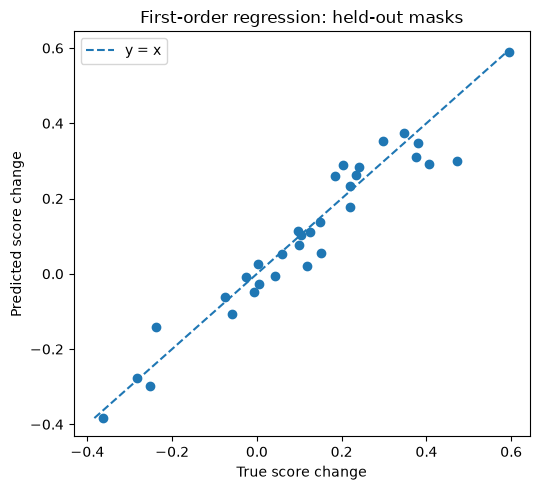

In [16]:
def regression_metrics(truth, prediction):
    truth, prediction = np.asarray(truth, dtype=float), np.asarray(prediction, dtype=float)
    if truth.shape != prediction.shape or truth.ndim != 1 or len(truth) < 2:
        raise ValueError("Metrics require two equal-length one-dimensional arrays with >=2 entries.")
    if not np.isfinite(truth).all() or not np.isfinite(prediction).all():
        raise ValueError("Metrics require finite values.")
    truth_varies = not np.allclose(truth, truth[0], rtol=0, atol=1e-12)
    pred_varies = not np.allclose(prediction, prediction[0], rtol=0, atol=1e-12)
    return {"MAE": float(mean_absolute_error(truth, prediction)),
            "Pearson": float(stats.pearsonr(truth, prediction)[0]) if truth_varies and pred_varies else np.nan,
            "Spearman": float(stats.spearmanr(truth, prediction)[0]) if truth_varies and pred_varies else np.nan,
            "R2": float(r2_score(truth, prediction)) if truth_varies else np.nan}


def design_diagnostics(design, name, require_full_rank=True):
    rank = int(np.linalg.matrix_rank(design))
    condition = float(np.linalg.cond(design))
    print(f"{name}: shape={design.shape}, rank={rank}/{design.shape[1]}, condition={condition:.3g}")
    if require_full_rank and rank != design.shape[1]:
        raise ValueError(f"{name} is not identifiable. Increase training masks or change the sampling seed "
                         "before examining test performance.")
    if condition > 1e8:
        warnings.warn(f"{name} is poorly conditioned; interpret coefficients cautiously.")
    return {"rank": rank, "columns": design.shape[1], "condition_number": condition}


def prediction_plot(truth, prediction, title, xlabel="True score change", ylabel="Predicted score change"):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.scatter(truth, prediction)
    limits = [float(min(np.min(truth), np.min(prediction))),
              float(max(np.max(truth), np.max(prediction)))]
    if limits[0] == limits[1]:
        limits = [limits[0] - 0.5, limits[1] + 0.5]
    ax.plot(limits, limits, "--", label="y = x")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend()
    fig.tight_layout()
    return fig


with costs.stage("first-order regression fit and evaluation"):
    linear_design_info = design_diagnostics(X_train, "First-order training design")
    first_order_model = LinearRegression(fit_intercept=False).fit(X_train, y_train)
    first_predictions = first_order_model.predict(X_test)
    first_metrics = regression_metrics(y_test, first_predictions)
display(pd.DataFrame([{"method": "first-order regression", **first_metrics}]))
fig = prediction_plot(y_test, first_predictions, "First-order regression: held-out masks")
figures["first_order_predictions"] = fig
plt.show()
plt.close(fig)

## 16. Explicit second-order approximation

Append $z_i z_j$ for every $i<j$ and fit a regression without an intercept. For eight heads this
uses $8+\binom{8}{2}=36$ features. Squared features are unnecessary because binary $z_i^2=z_i$.
Check full column rank before fitting; the same training and held-out masks support both models.
This is an explicit small-system comparator, not a scalable higher-order sketch.

Second-order training design: shape=(64, 36), rank=36/36, condition=19


,method,MAE,Pearson,Spearman,R2
0,first-order regression,0.044161,0.965184,0.963710,0.927900
1,explicit second-order regression,0.012484,0.997588,0.994868,0.994642


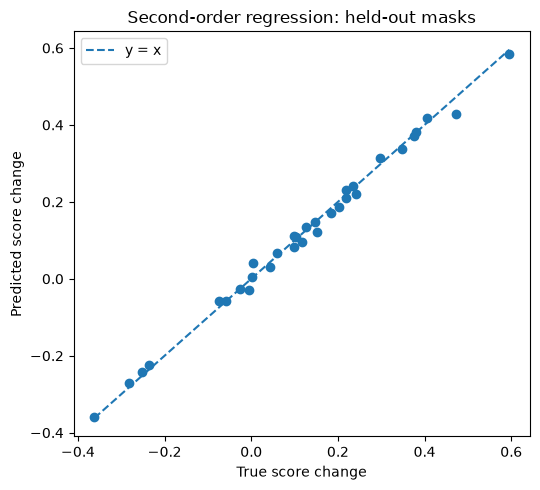

In [17]:
def second_order_features(masks):
    masks = np.asarray(masks, dtype=float)
    if masks.ndim != 2 or masks.shape[1] != n:
        raise ValueError(f"Expected a mask matrix with {n} columns.")
    products = np.column_stack([masks[:, i] * masks[:, j] for i, j in pair_indices])
    return np.column_stack([masks, products])


with costs.stage("second-order regression fit and evaluation"):
    X2_train, X2_test = second_order_features(X_train), second_order_features(X_test)
    quadratic_design_info = design_diagnostics(X2_train, "Second-order training design")
    second_order_model = LinearRegression(fit_intercept=False).fit(X2_train, y_train)
    second_predictions = second_order_model.predict(X2_test)
    second_metrics = regression_metrics(y_test, second_predictions)
approximation_results = pd.DataFrame([
    {"method": "first-order regression", **first_metrics},
    {"method": "explicit second-order regression", **second_metrics},
])
display(approximation_results)
fig = prediction_plot(y_test, second_predictions, "Second-order regression: held-out masks")
figures["second_order_predictions"] = fig
plt.show()
plt.close(fig)

## 17. Compare ranking quality

Rank interventions from **most harmful to least harmful**: smallest signed score change first.
Top-k overlap is the intersection size divided by k, rather than Jaccard overlap. Stable sorting
breaks ties by held-out row order for both truth and prediction. Spearman uses averaged ranks
for ties. Ranking quality and numerical prediction error answer different questions.

In [18]:
def ranking_metrics(truth, prediction):
    result = {"Spearman": regression_metrics(truth, prediction)["Spearman"]}
    true_order = np.argsort(truth, kind="stable")
    predicted_order = np.argsort(prediction, kind="stable")
    for k in (5, 10):
        if len(truth) >= k:
            result[f"top_{k}_overlap"] = len(set(true_order[:k]) & set(predicted_order[:k])) / k
    return result


ranking_results = pd.DataFrame([
    {"method": "first-order regression", **ranking_metrics(y_test, first_predictions)},
    {"method": "explicit second-order regression", **ranking_metrics(y_test, second_predictions)},
])
display(ranking_results)

,method,Spearman,top_5_overlap,top_10_overlap
0,first-order regression,0.963710,0.8,0.9
1,explicit second-order regression,0.994868,1.0,0.9


## 18. Compute cost accounting

The tracker was installed before the first forward. These are **actual incremental calls**:
repeated masks are cache hits. Thus the singleton stage can use fewer than n new forwards after
the demonstration, and training acquisition can reuse exact-intervention labels. Setup, baseline,
validation, and later sketch/diagnostic costs are separate stages. Timings synchronize CUDA.

Stage GPU peaks include the resident model and allocator reservations, so they are not additive.
The elapsed wall time includes loading, analysis, plotting, and time between manually run cells;
`forward_seconds` isolates measured forward-call time. CPU GPU-memory fields are `NaN`.
The final summary in section 21 refreshes these numbers after sketching.

In [19]:
def cost_tables():
    stages = pd.DataFrame(costs.stages)
    totals = costs.summary()
    totals["distinct_binary_masks_evaluated"] = len(mask_cache)
    totals["distinct_scaling_points_evaluated"] = len(scaling_cache) if "scaling_cache" in globals() else 0
    assert int(stages.model_evaluations.sum()) == costs.model_evaluations
    return stages, pd.DataFrame([totals])


stage_costs, total_costs = cost_tables()
display(stage_costs)
display(total_costs)

,stage,model_evaluations,mask_requests,mask_cache_hits,wall_seconds,peak_allocated_mib,peak_reserved_mib
0,model loading,0,0,0,220.589897,635.514160,690.0
1,sanity check,1,0,0,1.545457,646.637695,690.0
2,activation cache inspection,1,0,0,0.060049,646.637695,690.0
3,baseline score,1,0,0,0.059408,646.637695,690.0
4,mask and hook sanity checks,2,3,2,0.116376,646.637695,690.0
5,exact single interventions,7,8,1,0.412796,646.637695,690.0
6,exact pair interventions,28,28,0,1.285629,646.637695,690.0
7,random-mask training acquisition,38,64,26,1.670242,646.637695,690.0
8,held-out test acquisition,24,32,8,0.877294,646.637695,690.0
9,first-order regression fit and evaluation,0,0,0,0.031288,643.639648,690.0


,model_evaluations,mask_requests,mask_cache_hits,forward_seconds,elapsed_wall_seconds,peak_allocated_mib,peak_reserved_mib,distinct_binary_masks_evaluated,distinct_scaling_points_evaluated
0,102,135,37,5.592337,228.344634,646.637695,690.0,99,0


## 19. Toy directional sketching baseline

Define a separate continuous response $G(u)$ by scaling head $i$ by $1+u_i$.
Then $F(z)=G(-z)$ for binary ablations. For random Rademacher directions $r\in\{-1,+1\}^n$,
measure

$$d_r=\frac{G(\epsilon r)-G(-\epsilon r)}{2\epsilon}\approx r^\top g,
\qquad g=\nabla G(0),\quad \epsilon=0.05.$$

Solve $R\hat g\approx d$ with least squares. **Compare $-\hat g$ with exact ablation effects**:
increasing a head's scale has the opposite sign from removing it. Even perfect reconstruction of
the local gradient need not predict a full unit-sized ablation. Optionally compare against
coordinate finite differences to separate local reconstruction error from finite-ablation nonlinearity.
This coordinate reference is itself a finite-difference approximation, not an exact autograd gradient;
directional and coordinate truncation errors can differ because their perturbation norms differ.

Use shared prefixes for k = 4, 8, 16, 32, 64; the k=4 case is intentionally underdetermined.
Without sparsity or another prior, fewer than n independent measurements cannot identify an arbitrary
n-dimensional gradient. Each central-difference measurement costs **two forwards**, with duplicate
endpoints cached. k=16/32/64 for n=8 are implementation checks, not evidence of evaluation savings.
No budget is selected using held-out performance; the final row uses the prespecified largest k.
All accuracy metrics in the budget table evaluate `(-gradient) @ mask` against `y_test` on the
same held-out masks used for regression. Singleton and coordinate-reference values are shown
only as component diagnostics and plots, without presenting them as held-out accuracy metrics.

Directional measurements:   0%|          | 0/64 [00:00<?, ?it/s]

Coordinate finite differences:   0%|          | 0/8 [00:00<?, ?it/s]

,k,rank,identifiable,condition_number,nominal_forward_evaluations,actual_endpoint_evaluations,evaluation_split,n_test,MAE,Pearson,Spearman,R2
0,4,4,False,inf,8,8,held-out test masks,32,0.176385,0.806897,0.670884,0.030841
1,8,7,False,inf,16,16,held-out test masks,32,0.120778,0.856379,0.839443,0.468470
2,16,8,True,5.526746,32,28,held-out test masks,32,0.119999,0.862209,0.836510,0.453797
3,32,8,True,2.077262,64,52,held-out test masks,32,0.119992,0.862230,0.836510,0.453825
4,64,8,True,1.717127,128,100,held-out test masks,32,0.119991,0.862249,0.836510,0.453847


Component reference diagnostics; these are not held-out performance metrics:


,component,exact_ablation_effect,reconstructed_effect,negative_coordinate_gradient
0,L0H0,-0.167687,-0.261559,-0.261641
1,L1H1,0.236439,0.189297,0.189304
2,L2H2,0.105231,0.148701,0.148706
3,L3H3,0.242696,0.354579,0.354643
4,L4H4,-0.185747,-0.230528,-0.230627
5,L5H5,-0.066962,-0.201394,-0.201445
6,L6H6,-0.016735,-0.013749,-0.013657
7,L7H7,-0.003049,-0.004543,-0.004425


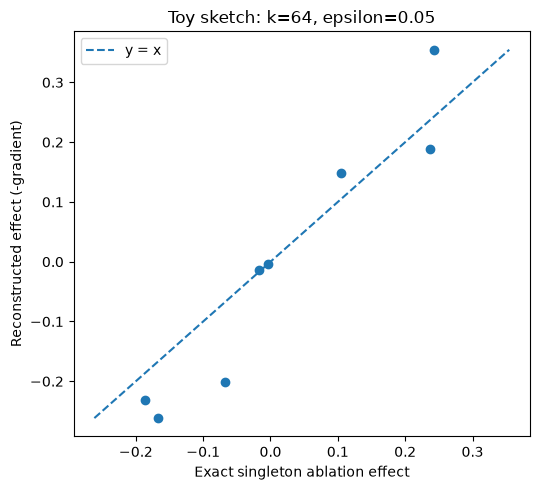

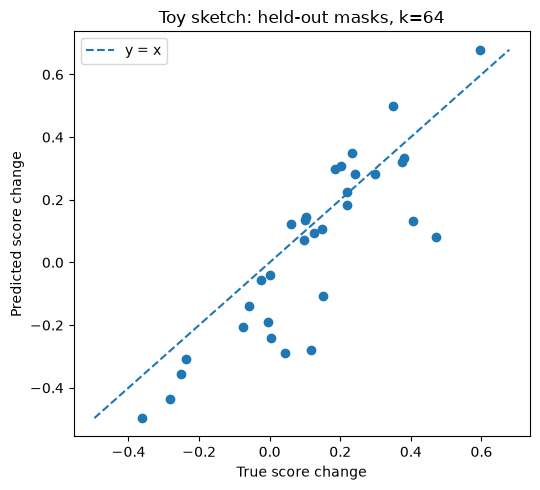

Singleton reference: 8 ablation forwards + one baseline.
Each sketch measurement uses two endpoints; underdetermined estimates are minimum-norm solutions.


In [20]:
if EPSILON <= 0 or not np.isfinite(EPSILON):
    raise ValueError("EPSILON must be finite and positive.")
if not SKETCH_BUDGETS or any(not isinstance(k, int) or k < 1 for k in SKETCH_BUDGETS):
    raise ValueError("Sketch budgets must be positive integers.")
sketch_budgets = sorted(set(SKETCH_BUDGETS))
scaling_cache = {tuple(np.zeros(n).tolist()): baseline_score}


def evaluate_scaling(offsets):
    offsets = np.asarray(offsets, dtype=np.float64)
    if offsets.shape != (n,) or not np.isfinite(offsets).all():
        raise ValueError(f"Expected finite scaling offsets of shape {(n,)}.")
    key = tuple(float(value) for value in offsets)
    if key not in scaling_cache:
        scaling_cache[key] = scaled_head_score(model, tokens, components, 1 + offsets, logit_difference)
    return scaling_cache[key]


direction_rng = np.random.default_rng(SEED + 2)
directions = direction_rng.choice([-1.0, 1.0], size=(max(sketch_budgets), n))
direction_rows = []
with costs.stage("toy directional sketch acquisition"):
    sketch_start_calls = costs.model_evaluations
    for m, direction in enumerate(tqdm(directions, desc="Directional measurements"), start=1):
        plus = evaluate_scaling(EPSILON * direction)
        minus = evaluate_scaling(-EPSILON * direction)
        direction_rows.append({"measurement": m, "direction": tuple(direction.astype(int)),
                               "score_plus": plus, "score_minus": minus,
                               "directional_derivative": (plus - minus) / (2 * EPSILON),
                               "cumulative_endpoint_evaluations": costs.model_evaluations - sketch_start_calls})
directional_measurements = pd.DataFrame(direction_rows)

# Independent local reference, used only for diagnostics, never for sketch reconstruction.
local_gradient = None
if RUN_LOCAL_GRADIENT_CHECK:
    with costs.stage("coordinate-gradient diagnostics"):
        local_gradient = np.empty(n)
        for i in tqdm(range(n), desc="Coordinate finite differences"):
            offset = np.zeros(n)
            offset[i] = EPSILON
            local_gradient[i] = (evaluate_scaling(offset) - evaluate_scaling(-offset)) / (2 * EPSILON)

sketch_rows, sketch_estimates = [], {}
with costs.stage("toy sketch reconstruction and evaluation"):
    for k in sketch_budgets:
        R = directions[:k]
        d = directional_measurements["directional_derivative"].to_numpy()[:k]
        gradient_hat, _, rank, singular_values = np.linalg.lstsq(R, d, rcond=None)
        reconstructed_effects = -gradient_hat
        sketch_estimates[k] = reconstructed_effects
        endpoint_calls = int(directional_measurements.iloc[k - 1]["cumulative_endpoint_evaluations"])
        identifiable = int(rank) == n
        condition = float(singular_values[0] / singular_values[-1]) if identifiable else np.inf
        sketch_rows.append({"k": k, "rank": int(rank), "identifiable": identifiable,
                            "condition_number": condition, "nominal_forward_evaluations": 2 * k,
                            "actual_endpoint_evaluations": endpoint_calls,
                            "evaluation_split": "held-out test masks", "n_test": len(y_test),
                            **regression_metrics(y_test, X_test @ reconstructed_effects)})

sketch_results = pd.DataFrame(sketch_rows)
display(sketch_results)

chosen_k = max(sketch_budgets)
sketch_effects = sketch_estimates[chosen_k]
component_diagnostics = pd.DataFrame({"component": component_names,
                                      "exact_ablation_effect": exact_effects,
                                      "reconstructed_effect": sketch_effects})
if local_gradient is not None:
    component_diagnostics["negative_coordinate_gradient"] = -local_gradient
print("Component reference diagnostics; these are not held-out performance metrics:")
display(component_diagnostics)
fig = prediction_plot(exact_effects, sketch_effects, f"Toy sketch: k={chosen_k}, epsilon={EPSILON}",
                      xlabel="Exact singleton ablation effect", ylabel="Reconstructed effect (-gradient)")
figures["toy_sketch_singleton_effects"] = fig
plt.show()
plt.close(fig)

sketch_predictions = X_test @ sketch_effects
sketch_test_metrics = regression_metrics(y_test, sketch_predictions)
fig = prediction_plot(y_test, sketch_predictions, f"Toy sketch: held-out masks, k={chosen_k}")
figures["toy_sketch_predictions"] = fig
plt.show()
plt.close(fig)
print(f"Singleton reference: {n} ablation forwards + one baseline.")
print("Each sketch measurement uses two endpoints; underdetermined estimates are minimum-norm solutions.")

## 20. Optional second-order directional test

Reuse the same endpoints and baseline to compute

$$q_r=\frac{G(\epsilon r)-2G(0)+G(-\epsilon r)}{\epsilon^2}\approx r^\top H r.$$

No additional model forwards are required. Rademacher directions have length $\sqrt n$, so
`curvature_per_unit_direction = q_r/n` helps interpret direction magnitude. Central finite
differences have truncation and floating-point error, amplified by $1/\epsilon^2$ for curvature.
Before drawing conclusions, repeat with several epsilon values and seeds. Large values alone
do not establish useful higher-order structure; check stability and improvement in prediction.
This exploratory section does not reconstruct the Hessian. Rademacher quadratic forms also
confound individual diagonal entries into their trace, which limits possible reconstruction.

In [21]:
curvature_results = pd.DataFrame()
if RUN_CURVATURE:
    with costs.stage("directional curvature (reused endpoints)"):
        before_curvature = costs.model_evaluations
        curvature_results = directional_measurements[["measurement", "direction"]].copy()
        curvature_results["epsilon"] = EPSILON
        curvature_results["directional_curvature"] = (
            directional_measurements["score_plus"] - 2 * baseline_score
            + directional_measurements["score_minus"]
        ) / EPSILON**2
        curvature_results["curvature_per_unit_direction"] = curvature_results["directional_curvature"] / n
        assert costs.model_evaluations == before_curvature
    display(curvature_results)
    display(curvature_results[["directional_curvature", "curvature_per_unit_direction"]].describe())
else:
    print("Exploratory curvature section disabled.")

,measurement,direction,epsilon,directional_curvature,curvature_per_unit_direction
0,1,"(1, -1, 1, -1, 1, -1, -1, 1)",0.05,0.176239,0.022030
1,2,"(1, -1, 1, 1, -1, -1, -1, -1)",0.05,0.175476,0.021935
2,3,"(-1, 1, 1, 1, -1, 1, -1, -1)",0.05,0.405502,0.050688
3,4,"(-1, 1, 1, 1, 1, 1, -1, -1)",0.05,0.330353,0.041294
4,5,"(1, 1, -1, 1, 1, 1, 1, -1)",0.05,0.187302,0.023413
...,...,...,...,...,...
59,60,"(-1, -1, -1, -1, 1, -1, 1, -1)",0.05,0.399399,0.049925
60,61,"(-1, 1, -1, -1, 1, -1, -1, -1)",0.05,0.098419,0.012302
61,62,"(-1, 1, -1, -1, -1, -1, -1, -1)",0.05,0.356674,0.044584
62,63,"(1, 1, -1, 1, -1, -1, -1, -1)",0.05,-0.140381,-0.017548


,directional_curvature,curvature_per_unit_direction
count,64.000000,64.000000
mean,0.215262,0.026908
std,0.259885,0.032486
min,-0.437546,-0.054693
25%,0.048828,0.006104
50%,0.218773,0.027347
75%,0.362015,0.045252
max,0.720978,0.090122


## 21. Results summary

All three rows below predict **the same held-out mask score changes**, including the toy sketch's
linear prediction `(-gradient) @ mask`. Gradient-versus-singleton reference values and plots appear
separately in section 19; all accuracy and ranking metrics use the held-out masks.

`model_evaluations` reports **actual new forwards executed in each method's acquisition stage**,
after cache reuse. `standalone_acquisition_evaluations` separately estimates a comparable budget
including one baseline, excluding test labels, setup, and diagnostics: 64 distinct training
scores for either regression, or one baseline plus distinct sketch endpoints. Actual regression
acquisition is cheaper here because it reuses earlier exact-intervention measurements; the standalone
column makes that dependency explicit. Both regressions share the same training data, so their counts
must not be summed. The full stage ledger includes every notebook forward, including exact-reference
and validation costs. Failed forward attempts, if any, are counted and flagged in `forward_log`.

In [22]:
def stage_evaluations(name):
    return sum(row["model_evaluations"] for row in costs.stages if row["stage"] == name)


sketch_endpoint_calls = int(sketch_results.set_index("k").loc[chosen_k, "actual_endpoint_evaluations"])
experiment_summary = pd.DataFrame([
    {"method": "first-order regression",
     "model_evaluations": stage_evaluations("random-mask training acquisition"), **first_metrics,
     "standalone_acquisition_evaluations": len(train_keys), "evaluation_split": "held-out test masks"},
    {"method": "explicit second-order regression",
     "model_evaluations": stage_evaluations("random-mask training acquisition"), **second_metrics,
     "standalone_acquisition_evaluations": len(train_keys), "evaluation_split": "held-out test masks"},
    {"method": "toy directional sketch",
     "model_evaluations": stage_evaluations("toy directional sketch acquisition"), **sketch_test_metrics,
     "standalone_acquisition_evaluations": 1 + sketch_endpoint_calls, "evaluation_split": "held-out test masks"},
])
display(experiment_summary)
stage_costs, total_costs = cost_tables()
display(stage_costs)
display(total_costs)
for label in ("exact single interventions", "exact pair interventions", "random-mask training acquisition"):
    print(f"{label}: {stage_evaluations(label)} new model evaluations")
print("Total actual notebook model evaluations:", costs.model_evaluations)

heldout_predictions = test_data.copy()
heldout_predictions["first_order_prediction"] = first_predictions
heldout_predictions["second_order_prediction"] = second_predictions
heldout_predictions["toy_sketch_prediction"] = sketch_predictions

,method,model_evaluations,MAE,Pearson,Spearman,R2,standalone_acquisition_evaluations,evaluation_split
0,first-order regression,38,0.044161,0.965184,0.963710,0.927900,64,held-out test masks
1,explicit second-order regression,38,0.012484,0.997588,0.994868,0.994642,64,held-out test masks
2,toy directional sketch,100,0.119991,0.862249,0.836510,0.453847,101,held-out test masks


,stage,model_evaluations,mask_requests,mask_cache_hits,wall_seconds,peak_allocated_mib,peak_reserved_mib
0,model loading,0,0,0,220.589897,635.514160,690.0
1,sanity check,1,0,0,1.545457,646.637695,690.0
2,activation cache inspection,1,0,0,0.060049,646.637695,690.0
3,baseline score,1,0,0,0.059408,646.637695,690.0
4,mask and hook sanity checks,2,3,2,0.116376,646.637695,690.0
5,exact single interventions,7,8,1,0.412796,646.637695,690.0
6,exact pair interventions,28,28,0,1.285629,646.637695,690.0
7,random-mask training acquisition,38,64,26,1.670242,646.637695,690.0
8,held-out test acquisition,24,32,8,0.877294,646.637695,690.0
9,first-order regression fit and evaluation,0,0,0,0.031288,643.639648,690.0


,model_evaluations,mask_requests,mask_cache_hits,forward_seconds,elapsed_wall_seconds,peak_allocated_mib,peak_reserved_mib,distinct_binary_masks_evaluated,distinct_scaling_points_evaluated
0,218,135,37,10.203512,234.043375,646.637695,690.0,99,117


exact single interventions: 7 new model evaluations
exact pair interventions: 28 new model evaluations
random-mask training acquisition: 38 new model evaluations
Total actual notebook model evaluations: 218


### Interpretation guide

1. If second-order regression improves held-out error and ranking substantially, nonlinear component
   interactions may matter for this prompt and mask distribution. One small split cannot establish
   statistical significance: repeat across prompts, seeds, and intervention densities. Extra parameters
   can also hurt generalization; examine rank and conditioning before interpreting coefficients.
2. Reconstruction with fewer **actual model evaluations** than exact reference acquisition would
   motivate further sketch development. Count two endpoints per central-difference measurement and
   a baseline where needed. Here n=8 and k=16/32/64 do not demonstrate such savings. A k<n minimum-norm
   solution is underdetermined without additional structure. Distinguish local gradient recovery
   from prediction of complete ablations.
3. Curvature that is stable across step sizes and large relative to first-order changes motivates
   testing a higher-order sketch; validate whether it improves held-out causal predictions.
4. These are toy experiments, **not MIB benchmark results**. One factual prompt and eight arbitrary
   heads cannot support claims about circuit-discovery quality, edge recovery, or benchmark efficiency.

## 22. Save results

Create a UTC-timestamped, uniquely suffixed directory under `results/`. Exclusive creation prevents
silent overwrites. Save the requested CSVs, all plots, the actual cost ledger, measured mask labels,
directions, and configuration/version metadata so results can be inspected and reproduced.

In [23]:
def csv_ready(frame):
    frame = frame.copy()
    for column in ("mask", "direction"):
        if column in frame:
            frame[column] = frame[column].map(lambda values: json.dumps([int(value) for value in values]))
    return frame


run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ") + "_" + uuid4().hex[:8]
run_dir = RESULTS_ROOT / run_id
run_dir.mkdir(parents=True, exist_ok=False)
stage_costs, total_costs = cost_tables()
tables = {
    "single_effects": single_effects,
    "pairwise_interactions": pairwise_interactions,
    "approximation_results": approximation_results,
    "experiment_summary": experiment_summary,
    "ranking_results": ranking_results,
    "training_masks": train_data,
    "heldout_predictions": heldout_predictions,
    "sketch_results": sketch_results,
    "sketch_component_diagnostics": component_diagnostics,
    "directional_measurements": directional_measurements,
    "stage_costs": stage_costs,
    "total_costs": total_costs,
    "forward_log": pd.DataFrame(costs.forward_log),
}
if local_gradient is not None:
    tables["local_gradient_reference"] = pd.DataFrame({"component": component_names,
                                                       "local_gradient": local_gradient,
                                                       "exact_ablation_effect": exact_effects})
if not curvature_results.empty:
    tables["directional_curvature"] = curvature_results
for name, frame in tables.items():
    csv_ready(frame).to_csv(run_dir / f"{name}.csv", index=False, mode="x")
for name, figure in figures.items():
    figure.savefig(run_dir / f"{name}.png", dpi=160, bbox_inches="tight")

configuration = {
    "seed": SEED, "model": "gpt2-small", "prompt": PROMPT, "prepend_bos": True,
    "correct_token": CORRECT_TOKEN, "incorrect_token": INCORRECT_TOKEN,
    "correct_token_id": correct_id, "incorrect_token_id": incorrect_id,
    "baseline_score": baseline_score, "components": components,
    "head_hooks": head_hook_names, "intervention_positions": "all positions",
    "n_train": N_TRAIN, "n_test": N_TEST, "ablation_probability": ABLATION_PROBABILITY,
    "epsilon": EPSILON, "sketch_budgets": sketch_budgets, "chosen_k": chosen_k,
    "local_gradient_check": RUN_LOCAL_GRADIENT_CHECK, "curvature": RUN_CURVATURE,
    "device": device, "gpu": torch.cuda.get_device_name() if device == "cuda" else None,
    "dtype": str(next(model.parameters()).dtype), "python": sys.version,
    "packages": package_versions, "linear_design": linear_design_info,
    "quadratic_design": quadratic_design_info,
    "summary_target": "held-out binary mask score changes",
    "summary_cost": "model_evaluations: actual acquisition forwards; standalone budget separately includes baseline",
    "timing_scope": "from before model loading through pre-export snapshot; includes cell idle time",
}
with (run_dir / "configuration.json").open("x", encoding="utf-8") as handle:
    json.dump(configuration, handle, indent=2)
print("Saved results to:", run_dir.resolve())
print("CSVs:", len(tables), "| PNG plots:", len(figures))
release_cuda_cache()

Saved results to: H:\GenAI Research\sketch_prune\results\20261014T213306_084641Z_6da48ba0
CSVs: 15 | PNG plots: 5


## 23. Next Steps Toward MIB

- Replace the factual next-token score with an IOI task metric and evaluate across prompts.
- Operate on MIB-defined edges rather than only attention heads.
- Reproduce EAP / EAP-IG baselines using the benchmark's intervention and metric conventions.
- Compare against MAttr.
- Measure CPR and CMD using the benchmark's exact definitions and reporting protocol.
- Implement randomized higher-order tensor sketches with explicit recovery assumptions.
- Investigate screening followed by exact verification as a hybrid strategy.
- Compare quality versus number of model evaluations, alongside runtime and peak memory.

Before scaling up: sweep epsilon, random seeds, head selections, and mask density; test a larger
component set where compression is meaningful. Keep acquisition, reference construction, and
held-out validation costs distinct. Assess variance and task-level generalization before claiming
improved circuit discovery.